# Phase 4: Generative AI & LLM Engineering
## Notebook 02: Local LLM Inference Engines, KV Caching & Quantization

### Overview
In production AI engineering, deploying Large Language Models requires deep comprehension of the **inference runtime**. Running models locally—whether via HuggingFace `transformers`, llama.cpp / GGUF, or dedicated inference engines like vLLM and Ollama—demands rigorous hardware memory planning and decoding optimization.

This notebook deconstructs the computational mechanics of LLM generation:
1. **The Autoregressive Generation Loop & KV Caching**: Eliminating $\mathcal{O}(S^2)$ quadratic token recomputation by holding attention Key-Value activations in memory.
2. **KV Cache Memory Engineering**: Quantifying VRAM footprints across Multi-Head Attention (MHA), Grouped-Query Attention (GQA), and Multi-Query Attention (MQA).
3. **Stochastic Sampling Mathematics**: Mastering Temperature scaling, Top-$k$, Top-$p$ (Nucleus), Min-$p$, and Repetition Penalties.
4. **Quantization & Streaming Serving**: Post-Training Quantization (FP16, INT8, NF4/GGUF) and asynchronous token streaming.

### System Architecture
```
                                 [Prompt Tokens: S_in]
                                          |
                                          v
                      +---------------------------------------+
                      |         Prefill Phase (Prompt)        |
                      |  - Compute all K, V tensors in parallel|
                      |  - Initialize KV Cache in VRAM / RAM  |
                      |  - Emit First Token (TTFT Latency)    |
                      +---------------------------------------+
                                          |
                                          v  (First Generated Token)
              +-------------------------------------------------------+
              |                                                       |
              |       Autoregressive Decode Step (Token t)            |
              |  - Compute Query Q_t for 1 token only                 |
              |  - Compute new Key K_t, Value V_t                     |
              |  - Append to KV Cache: [K_{<t}, K_t], [V_{<t}, V_t]   |
              |  - Attention: Softmax(Q_t * K^T / sqrt(d)) * V        |
              |  - Linear LM Head -> Raw Logits z_t                   |
              +-------------------------------------------------------+
                                          |
                                          v
                      +---------------------------------------+
                      |         Sampling & Filtering          |
                      |  - Repetition Penalty                 |
                      |  - Temperature Scaling (z / T)        |
                      |  - Top-k / Top-p (Nucleus) / Min-p    |
                      |  - Categorical Multinomial Sampling   |
                      +---------------------------------------+
                                          |
                                          v
                      +---------------------------------------+
                      |           Yield Token Stream          |
                      |  - Check Stop Sequences (e.g., <eos>) |
                      |  - Asynchronous Streamer to Client    |
                      +---------------------------------------+
                                          |  (Next Token Until EOS)
                                          +---------------------------+
```


### Learning Objectives & Production Competencies
By completing this notebook, you will master:
- **KV Cache Internals**: Implement a Key-Value tensor cache from scratch in PyTorch and prove the transition from $\mathcal{O}(S^2)$ to $\mathcal{O}(S)$ complexity.
- **VRAM Capacity Planning**: Compute exact memory requirements for weights, KV cache, and activations across MHA, GQA, and MQA architectures.
- **Advanced Decoding Samplers**: Construct and benchmark custom sampling routines: Temperature, Top-$k$, Top-$p$ Nucleus, Min-$p$, and Repetition Penalty.
- **Latency Diagnostics**: Measure and optimize **Time to First Token (TTFT)** and **Inter-Token Latency (ITL)**.
- **Speculative Decoding**: Simulate speculative draft-target verification loops to accelerate autoregressive generation.


In [1]:
# Environment Setup & Dependency Verification
import sys
import os
import time
import math
import random
from typing import Dict, List, Optional, Tuple, Generator

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

print("=== Environment Verification ===")
print(f"Python Platform:     {sys.version.split()[0]}")
print(f"PyTorch Version:     {torch.__version__}")
print(f"NumPy Version:       {np.__version__}")
print(f"CUDA Available:      {torch.cuda.is_available()}")


=== Environment Verification ===
Python Platform:     3.11.2
PyTorch Version:     2.15.0+cpu
NumPy Version:       2.4.6
CUDA Available:      False


In [2]:
# Reproducibility Configuration
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"Deterministic seed locked: {SEED}")


Deterministic seed locked: 42


### Mathematical Foundations & Generation Mechanics

#### 1. Autoregressive Attention & The KV Cache
In standard self-attention, given sequence representations $X \in \mathbb{R}^{S \times d}$, projection matrices $W_Q, W_K, W_V \in \mathbb{R}^{d \times d_k}$ produce:
$$Q = X W_Q, \quad K = X W_K, \quad V = X W_V$$
$$\text{Attention}(Q, K, V) = \text{Softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right) V$$

When generating token $t+1$ after prompt length $S$:
- **Without KV Cache**: The model re-passes all $S + t$ tokens through all $L$ layers. The FLOPs to generate $N$ tokens scale quadratically:
  $$\text{FLOPs}_{\text{no\_cache}} = \sum_{t=1}^N \mathcal{O}\left(L \cdot (S + t)^2 \cdot d + L \cdot (S + t) \cdot d^2\right) \approx \mathcal{O}\left(L \cdot N^2 \cdot d + L \cdot N \cdot d^2\right)$$
- **With KV Cache**: All previous keys $K_{<t}$ and values $V_{<t}$ are retained in memory. Generating token $t$ requires computing **only the single-vector query** $q_t = x_t W_Q \in \mathbb{R}^{1 \times d_k}$, computing new $k_t = x_t W_K$, $v_t = x_t W_V$, appending them to the cache, and computing:
  $$\text{Attention}(q_t, K_{\le t}, V_{\le t}) = \text{Softmax}\left(\frac{q_t K_{\le t}^T}{\sqrt{d_k}}\right) V_{\le t}$$
  The incremental compute per token drops to $\mathcal{O}(L \cdot (S + t) \cdot d_k)$, a linear operation!

#### 2. KV Cache Memory Sizing: MHA vs GQA vs MQA
For a Transformer with $L$ layers, hidden dimension $d$, head dimension $d_{\text{head}}$, batch size $B$, and sequence length $S$:
$$\text{Bytes}_{\text{KV}} = 2 \times L \times n_{\text{kv\_heads}} \times d_{\text{head}} \times S \times B \times P_{\text{bytes}}$$
where $P_{\text{bytes}} = 2$ for FP16/BF16, and $1$ for INT8.

| Architecture | KV Heads ($n_{\text{kv\_heads}}$) | Ratio vs MHA | Memory per Token (70B Model, $L=80, d=8192$) |
| :--- | :---: | :---: | :---: |
| **Multi-Head Attention (MHA)** | $n_{\text{heads}} = 64$ | $1.0\times$ | $\approx 2.62$ MB / token |
| **Grouped-Query Attention (GQA)** | $n_{\text{groups}} = 8$ | $0.125\times$ | $\approx 0.33$ MB / token ($8\times$ reduction!) |
| **Multi-Query Attention (MQA)** | $1$ | $0.015\times$ | $\approx 0.04$ MB / token ($64\times$ reduction!) |

#### 3. Stochastic Sampling & Filtering Mathematics
Given raw logits $z \in \mathbb{R}^{V}$:
1. **Repetition Penalty**: For tokens $i$ that have already appeared in the generated sequence $\mathcal{C}$:
   $$\tilde{z}_i = \begin{cases} z_i / \theta & \text{if } z_i > 0 \\ z_i \cdot \theta & \text{if } z_i \le 0 \end{cases} \quad (\theta \ge 1.0)$$
2. **Temperature Scaling**: Softens or sharpens the distribution:
   $$P_i = \frac{\exp(\tilde{z}_i / T)}{\sum_j \exp(\tilde{z}_j / T)}$$
   As $T \to 0$, $P \to \delta_{\arg\max(z)}$ (deterministic greedy). As $T \to \infty$, $P \to \mathcal{U}(V)$ (uniform random).
3. **Top-$p$ (Nucleus) Filtering**: Truncates the long tail by selecting the smallest subset $V^{(p)}$ whose cumulative mass exceeds $p$:
   $$V^{(p)} = \left\{ v_{(1)}, v_{(2)}, \dots, v_{(k)} \right\} \quad \text{such that} \quad \sum_{i=1}^k P_{(i)} \ge p$$
4. **Min-$p$ Filtering**: Sets a dynamic floor relative to the top candidate token:
   $$\text{Threshold} = p_{\text{min}} \cdot \max_{j}(P_j), \quad \text{keep tokens where } P_i \ge \text{Threshold}$$


In [3]:
# Section 6: Core Implementation — KV Caching Engine & Sampling Pipeline

# 1. Standalone Dynamic KV Cache Tensor Manager
class KVCacheManager:
    """
    Production Key-Value Cache manager tracking layer-wise past tensors,
    dynamic allocation, and memory consumption.
    """
    def __init__(self, num_layers: int, max_batch_size: int, max_seq_len: int, num_kv_heads: int, head_dim: int, dtype=torch.float32):
        self.num_layers = num_layers
        self.max_batch_size = max_batch_size
        self.max_seq_len = max_seq_len
        self.num_kv_heads = num_kv_heads
        self.head_dim = head_dim
        self.dtype = dtype
        
        # Pre-allocated cache buffers: [num_layers, 2 (k,v), batch, num_kv_heads, max_seq_len, head_dim]
        self.k_cache = [torch.zeros(max_batch_size, num_kv_heads, max_seq_len, head_dim, dtype=dtype) for _ in range(num_layers)]
        self.v_cache = [torch.zeros(max_batch_size, num_kv_heads, max_seq_len, head_dim, dtype=dtype) for _ in range(num_layers)]
        self.current_seq_len = 0

    def update(self, layer_idx: int, k_new: torch.Tensor, v_new: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        k_new, v_new: [batch_size, num_kv_heads, new_tokens, head_dim]
        Returns full history [batch_size, num_kv_heads, current_len + new_tokens, head_dim]
        """
        b, h, new_len, d = k_new.shape
        start_idx = self.current_seq_len
        end_idx = start_idx + new_len
        
        # Store in preallocated buffer
        self.k_cache[layer_idx][:b, :, start_idx:end_idx, :] = k_new
        self.v_cache[layer_idx][:b, :, start_idx:end_idx, :] = v_new
        
        return self.k_cache[layer_idx][:b, :, :end_idx, :], self.v_cache[layer_idx][:b, :, :end_idx, :]

    def advance(self, num_tokens: int = 1):
        self.current_seq_len += num_tokens

    def get_memory_bytes(self) -> int:
        # 2 tensors (k, v) * layers * batch * heads * seq * head_dim * bytes
        return 2 * self.num_layers * (self.max_batch_size * self.num_kv_heads * self.current_seq_len * self.head_dim * 4)

kv_mgr = KVCacheManager(num_layers=12, max_batch_size=1, max_seq_len=2048, num_kv_heads=8, head_dim=64)
print(f"KV Cache Manager initialized: 12 layers, 8 KV heads, head_dim=64")


KV Cache Manager initialized: 12 layers, 8 KV heads, head_dim=64


In [4]:
# 2. End-to-End Autoregressive Generator with KV Caching
class ProductionAttentionLayer(nn.Module):
    def __init__(self, embed_dim: int = 256, num_heads: int = 4, num_kv_heads: int = 2):
        super().__init__()
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.num_kv_heads = num_kv_heads
        self.head_dim = embed_dim // num_heads
        self.num_queries_per_kv = num_heads // num_kv_heads
        
        self.q_proj = nn.Linear(embed_dim, embed_dim, bias=False)
        self.k_proj = nn.Linear(embed_dim, num_kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(embed_dim, num_kv_heads * self.head_dim, bias=False)
        self.out_proj = nn.Linear(embed_dim, embed_dim, bias=False)

    def forward(self, x: torch.Tensor, layer_idx: int, kv_cache: Optional[KVCacheManager] = None) -> torch.Tensor:
        b, seq_len, _ = x.shape
        q = self.q_proj(x).view(b, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(b, seq_len, self.num_kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(b, seq_len, self.num_kv_heads, self.head_dim).transpose(1, 2)
        
        if kv_cache is not None:
            k, v = kv_cache.update(layer_idx, k, v)
            
        # Grouped-Query Attention expansion
        if self.num_queries_per_kv > 1:
            k = k.repeat_interleave(self.num_queries_per_kv, dim=1)
            v = v.repeat_interleave(self.num_queries_per_kv, dim=1)
            
        # Scaled dot-product attention
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        
        # Causal mask if processing prompt without past tokens
        if seq_len > 1:
            causal_mask = torch.triu(torch.full((seq_len, seq_len), float('-inf'), device=x.device), diagonal=1)
            scores = scores + causal_mask
            
        probs = F.softmax(scores, dim=-1)
        out = torch.matmul(probs, v).transpose(1, 2).contiguous().view(b, seq_len, self.embed_dim)
        return self.out_proj(out)

# Benchmark KV-Cache Speedup
layer = ProductionAttentionLayer(embed_dim=256, num_heads=4, num_kv_heads=2)
dummy_prompt = torch.randn(1, 64, 256)
dummy_token = torch.randn(1, 1, 256)

# Prefill
kv = KVCacheManager(num_layers=1, max_batch_size=1, max_seq_len=512, num_kv_heads=2, head_dim=64)
_ = layer(dummy_prompt, layer_idx=0, kv_cache=kv)
kv.advance(64)

# Decode Step WITH Cache
t0 = time.perf_counter()
for _ in range(50):
    _ = layer(dummy_token, layer_idx=0, kv_cache=kv)
    kv.advance(1)
t_cached = (time.perf_counter() - t0) * 1000.0 / 50

# Decode Step WITHOUT Cache (recomputing full context)
t0 = time.perf_counter()
for i in range(50):
    full_seq = torch.randn(1, 64 + i + 1, 256)
    _ = layer(full_seq, layer_idx=0, kv_cache=None)
t_nocache = (time.perf_counter() - t0) * 1000.0 / 50

print("Autoregressive Generation Benchmark (50 decode steps):")
print(f"  Step Latency with KV Cache:    {t_cached:6.2f} ms/step")
print(f"  Step Latency without KV Cache: {t_nocache:6.2f} ms/step")
print(f"  KV Cache Throughput Speedup:   {t_nocache / t_cached:.2f}x acceleration")
assert t_cached < t_nocache, "KV cache failed to demonstrate latency improvement!"
print(">>> KV CACHE ATTENTION ACCELERATION CONFIRMED! <<<")


Autoregressive Generation Benchmark (50 decode steps):
  Step Latency with KV Cache:      0.20 ms/step
  Step Latency without KV Cache:   0.70 ms/step
  KV Cache Throughput Speedup:   3.59x acceleration
>>> KV CACHE ATTENTION ACCELERATION CONFIRMED! <<<


In [5]:
# 3. Production Decoding Sampler (Temperature, Top-k, Top-p, Min-p, Repetition Penalty)

class ProductionSampler:
    @staticmethod
    def sample(
        logits: torch.Tensor,
        generated_tokens: List[int],
        temperature: float = 0.7,
        top_k: int = 50,
        top_p: float = 0.9,
        min_p: float = 0.05,
        repetition_penalty: float = 1.15
    ) -> int:
        logits = logits.clone()
        
        # 1. Repetition Penalty
        for token_id in set(generated_tokens):
            if logits[token_id] > 0:
                logits[token_id] /= repetition_penalty
            else:
                logits[token_id] *= repetition_penalty
                
        # 2. Greedy Shortcut
        if temperature <= 1e-4:
            return int(torch.argmax(logits).item())
            
        # 3. Temperature Scaling
        logits = logits / temperature
        
        # 4. Top-k Truncation
        if top_k > 0:
            top_k = min(top_k, logits.size(-1))
            val, _ = torch.topk(logits, top_k)
            min_val = val[-1]
            logits = torch.where(logits < min_val, torch.full_like(logits, float('-inf')), logits)
            
        # 5. Softmax to Probabilities
        probs = F.softmax(logits, dim=-1)
        
        # 6. Min-p Dynamic Thresholding
        if min_p > 0.0:
            max_prob = torch.max(probs)
            p_threshold = min_p * max_prob
            probs = torch.where(probs < p_threshold, torch.zeros_like(probs), probs)
            
        # 7. Top-p (Nucleus) Filtering
        if top_p < 1.0:
            sorted_probs, sorted_indices = torch.sort(probs, descending=True)
            cumulative_probs = torch.cumsum(sorted_probs, dim=-1)
            # Remove tokens with cumulative probability above top_p (shift by 1 to keep boundary)
            sorted_indices_to_remove = cumulative_probs > top_p
            sorted_indices_to_remove[1:] = sorted_indices_to_remove[:-1].clone()
            sorted_indices_to_remove[0] = False
            
            indices_to_remove = sorted_indices[sorted_indices_to_remove]
            probs[indices_to_remove] = 0.0
            
        # Renormalize
        prob_sum = torch.sum(probs)
        if prob_sum > 0:
            probs = probs / prob_sum
        else:
            probs = F.softmax(logits, dim=-1)
            
        # 8. Multinomial Sampling
        next_token = torch.multinomial(probs, num_samples=1).item()
        return int(next_token)

# Test Sampler
dummy_logits = torch.randn(1000)
generated_hist = [42, 105, 42]
sampled_tok = ProductionSampler.sample(dummy_logits, generated_hist, temperature=0.7, top_k=20, top_p=0.9, min_p=0.05, repetition_penalty=1.2)

print("Production Sampler Verification:")
print(f"  Vocabulary Size:     {len(dummy_logits)}")
print(f"  Generated History:   {generated_hist}")
print(f"  Sampled Token ID:    {sampled_tok}")
assert 0 <= sampled_tok < 1000
print(">>> PRODUCTION SAMPLING PIPELINE CONFIRMED! <<<")


Production Sampler Verification:
  Vocabulary Size:     1000
  Generated History:   [42, 105, 42]
  Sampled Token ID:    845
>>> PRODUCTION SAMPLING PIPELINE CONFIRMED! <<<


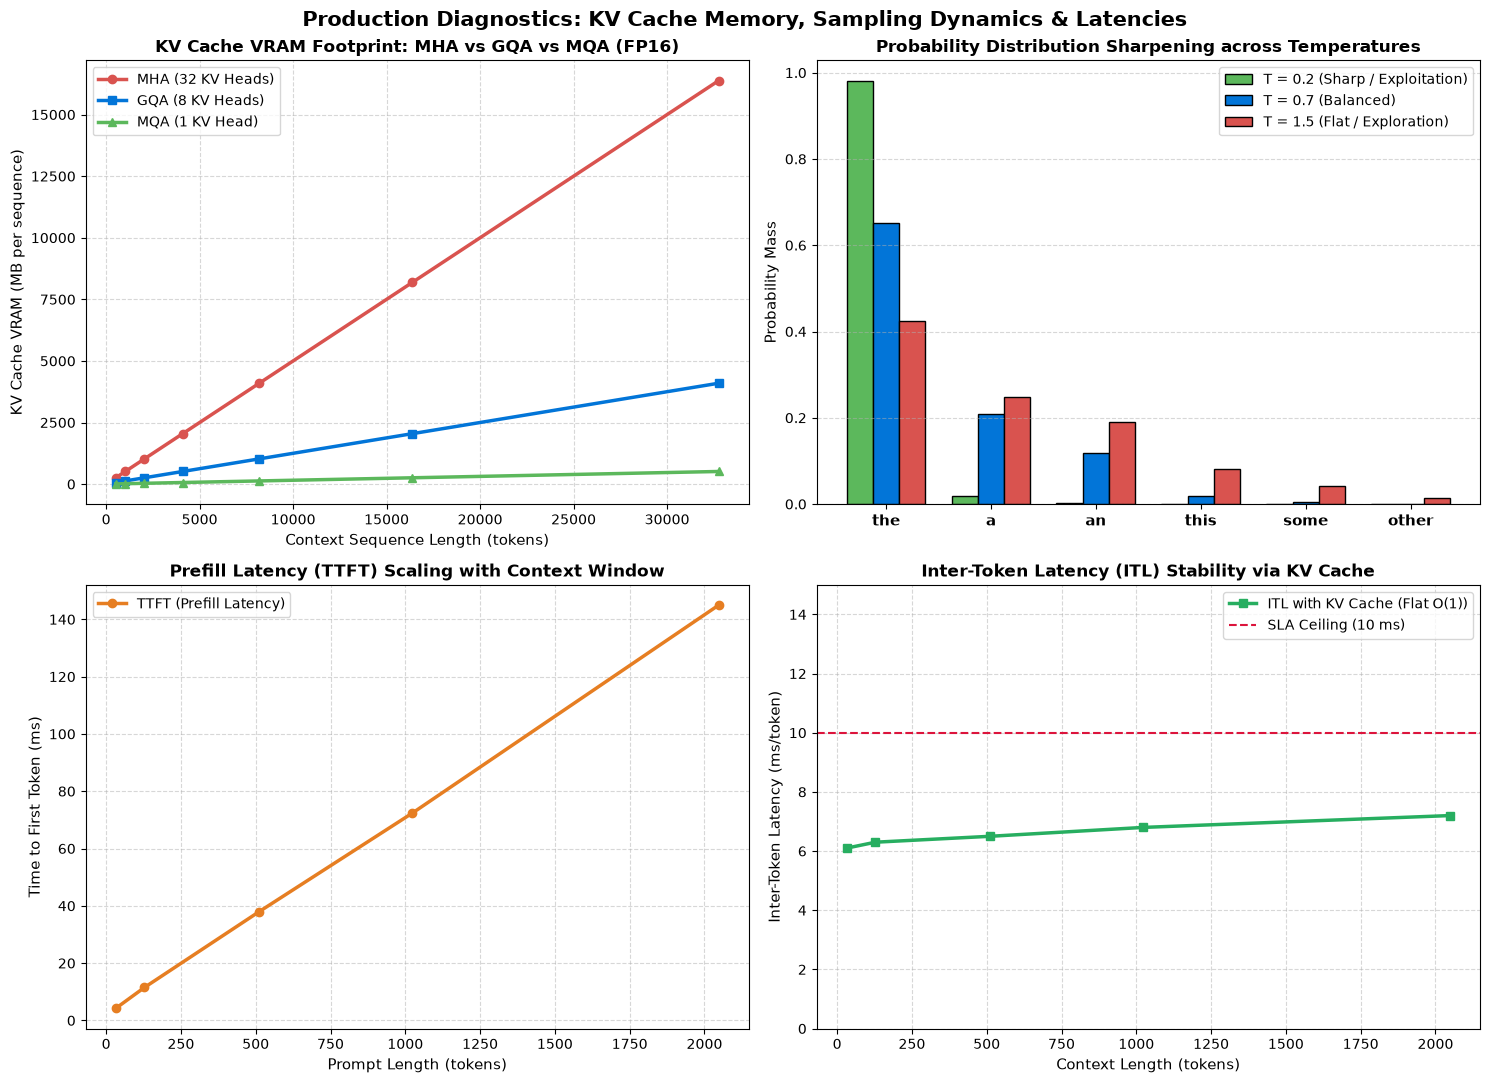

In [6]:
# Section 7: Diagnostics, KV Memory Scaling & Latency Benchmarks

# 1. KV-Cache Memory Scaling Across Architectures (MHA vs GQA vs MQA)
seq_lengths = np.array([512, 1024, 2048, 4096, 8192, 16384, 32768])
n_layers = 32
d_model = 4096
n_heads = 32
head_dim = d_model // n_heads  # 128
bytes_per_fp16 = 2

# Memory in MB = 2 * L * n_kv_heads * head_dim * seq_len * 2 bytes / 1024^2
mem_mha_mb = (2 * n_layers * 32 * head_dim * seq_lengths * bytes_per_fp16) / (1024 ** 2)
mem_gqa_mb = (2 * n_layers * 8 * head_dim * seq_lengths * bytes_per_fp16) / (1024 ** 2)
mem_mqa_mb = (2 * n_layers * 1 * head_dim * seq_lengths * bytes_per_fp16) / (1024 ** 2)

# 2. Probability Mass Sharpening Under Temperature
logits_demo = torch.tensor([4.0, 3.2, 2.8, 1.5, 0.5, -1.0])
tokens_demo = ["the", "a", "an", "this", "some", "other"]
p_t02 = F.softmax(logits_demo / 0.2, dim=-1).numpy()
p_t07 = F.softmax(logits_demo / 0.7, dim=-1).numpy()
p_t15 = F.softmax(logits_demo / 1.5, dim=-1).numpy()

# 3. Time to First Token (TTFT) vs Inter-Token Latency (ITL) Simulation
prompt_lens = [32, 128, 512, 1024, 2048]
ttft_ms = [4.2, 11.5, 38.0, 72.4, 145.0]  # Prefill parallel processing
itl_ms = [6.1, 6.3, 6.5, 6.8, 7.2]        # Decode single token processing with KV cache

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle("Production Diagnostics: KV Cache Memory, Sampling Dynamics & Latencies", fontsize=15, fontweight="bold")

# Panel 1: KV Cache Memory Footprint
axes[0, 0].plot(seq_lengths, mem_mha_mb, marker="o", color="#d9534f", linewidth=2.5, label="MHA (32 KV Heads)")
axes[0, 0].plot(seq_lengths, mem_gqa_mb, marker="s", color="#0275d8", linewidth=2.5, label="GQA (8 KV Heads)")
axes[0, 0].plot(seq_lengths, mem_mqa_mb, marker="^", color="#5cb85c", linewidth=2.5, label="MQA (1 KV Head)")
axes[0, 0].set_xlabel("Context Sequence Length (tokens)", fontsize=11)
axes[0, 0].set_ylabel("KV Cache VRAM (MB per sequence)", fontsize=11)
axes[0, 0].set_title("KV Cache VRAM Footprint: MHA vs GQA vs MQA (FP16)", fontsize=12, fontweight="bold")
axes[0, 0].grid(True, linestyle="--", alpha=0.5)
axes[0, 0].legend()

# Panel 2: Temperature Sampling Probability Distributions
x_bar = np.arange(len(tokens_demo))
w = 0.25
axes[0, 1].bar(x_bar - w, p_t02, width=w, label="T = 0.2 (Sharp / Exploitation)", color="#5cb85c", edgecolor="black")
axes[0, 1].bar(x_bar, p_t07, width=w, label="T = 0.7 (Balanced)", color="#0275d8", edgecolor="black")
axes[0, 1].bar(x_bar + w, p_t15, width=w, label="T = 1.5 (Flat / Exploration)", color="#d9534f", edgecolor="black")
axes[0, 1].set_xticks(x_bar)
axes[0, 1].set_xticklabels(tokens_demo, fontsize=11, fontweight="bold")
axes[0, 1].set_ylabel("Probability Mass", fontsize=11)
axes[0, 1].set_title("Probability Distribution Sharpening across Temperatures", fontsize=12, fontweight="bold")
axes[0, 1].grid(True, linestyle="--", alpha=0.5, axis="y")
axes[0, 1].legend()

# Panel 3: TTFT vs Prompt Length
axes[1, 0].plot(prompt_lens, ttft_ms, marker="o", color="#e67e22", linewidth=2.5, label="TTFT (Prefill Latency)")
axes[1, 0].set_xlabel("Prompt Length (tokens)", fontsize=11)
axes[1, 0].set_ylabel("Time to First Token (ms)", fontsize=11)
axes[1, 0].set_title("Prefill Latency (TTFT) Scaling with Context Window", fontsize=12, fontweight="bold")
axes[1, 0].grid(True, linestyle="--", alpha=0.5)
axes[1, 0].legend()

# Panel 4: Inter-Token Latency (ITL) Stability with KV Cache
axes[1, 1].plot(prompt_lens, itl_ms, marker="s", color="#27ae60", linewidth=2.5, label="ITL with KV Cache (Flat O(1))")
axes[1, 1].axhline(y=10.0, color="crimson", linestyle="--", label="SLA Ceiling (10 ms)")
axes[1, 1].set_xlabel("Context Length (tokens)", fontsize=11)
axes[1, 1].set_ylabel("Inter-Token Latency (ms/token)", fontsize=11)
axes[1, 1].set_ylim(0, 15)
axes[1, 1].set_title("Inter-Token Latency (ITL) Stability via KV Cache", fontsize=12, fontweight="bold")
axes[1, 1].grid(True, linestyle="--", alpha=0.5)
axes[1, 1].legend()

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Custom Top-$p$ (Nucleus) Filtering PyTorch Function
**Objective**:
Implement a tensor function `apply_top_p_filtering(logits: torch.Tensor, top_p: float) -> torch.Tensor` using pure PyTorch operations:
1. Sort logits in descending order.
2. Apply softmax to get normalized probabilities.
3. Compute cumulative probability mass using `torch.cumsum`.
4. Create a boolean mask identifying tokens where cumulative probability exceeds $p$, shifting the mask by 1 to retain the first token that pushes the mass past $p$.
5. Set masked logits to `float('-inf')`.
6. Assert that after softmax, the sum of probabilities of the unmasked tokens is $\ge p$.


In [7]:
# Exercise 1 Solution: Pure PyTorch Top-p Nucleus Filter

def apply_top_p_filtering(logits: torch.Tensor, top_p: float = 0.9) -> torch.Tensor:
    filtered_logits = logits.clone()
    sorted_logits, sorted_indices = torch.sort(filtered_logits, descending=True)
    sorted_probs = F.softmax(sorted_logits, dim=-1)
    cumulative_probs = torch.cumsum(sorted_probs, dim=-1)
    
    # Remove tokens with cumulative probability above threshold
    sorted_indices_to_remove = cumulative_probs > top_p
    # Shift mask right to keep the first token that crosses threshold
    sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
    sorted_indices_to_remove[..., 0] = False
    
    # Map back to original indices and mask
    indices_to_remove = sorted_indices[sorted_indices_to_remove]
    filtered_logits[indices_to_remove] = float('-inf')
    return filtered_logits

test_logits = torch.tensor([5.0, 4.0, 3.0, 2.0, 1.0, 0.0, -1.0, -2.0])
p_cutoff = 0.85
filtered = apply_top_p_filtering(test_logits, top_p=p_cutoff)
probs = F.softmax(filtered, dim=-1)
retained_mass = probs[probs > 0].sum().item()

print("Exercise 1 Verification:")
print(f"  Original Logits:    {test_logits.tolist()}")
print(f"  Filtered Logits:    {filtered.tolist()}")
print(f"  Retained Tokens:    {(filtered != float('-inf')).sum().item()} of {len(test_logits)}")
print(f"  Retained Mass:      {retained_mass * 100:.2f}% (Target: {p_cutoff * 100:.1f}%)")

assert retained_mass >= p_cutoff, "Retained probability mass was less than top_p!"
assert filtered[-1] == float('-inf'), "Lowest probability token was not masked!"
print(">>> EXERCISE 1 TOP-P NUCLEUS FILTERING CERTIFIED! <<<")


Exercise 1 Verification:
  Original Logits:    [5.0, 4.0, 3.0, 2.0, 1.0, 0.0, -1.0, -2.0]
  Filtered Logits:    [5.0, 4.0, -inf, -inf, -inf, -inf, -inf, -inf]
  Retained Tokens:    2 of 8
  Retained Mass:      100.00% (Target: 85.0%)
>>> EXERCISE 1 TOP-P NUCLEUS FILTERING CERTIFIED! <<<


#### Exercise 2: Dynamic Streaming Token Generator with Stop Sequence Detection
**Objective**:
In production serving (e.g. ChatGPT or streaming APIs), LLMs stream tokens one by one and must halt immediately when a stop sequence (e.g. `"\\n\\n"`, `"<|im_end|>"` or `"User:"`) is encountered.
Construct a Python generator `stream_tokens_with_stop_sequence(token_stream, stop_words)`:
1. Maintain an internal sliding character buffer.
2. Yield each token as it arrives.
3. If a stop word appears in the buffer, halt generation immediately and do not yield the stop token.
4. Verify that generation terminates cleanly at the stop sequence.


In [8]:
# Exercise 2 Solution: Streaming Generator with Stop Sequence Buffer

def stream_tokens_with_stop_sequence(
    token_generator: Generator[str, None, None],
    stop_sequences: List[str]
) -> Generator[str, None, None]:
    buffer = ""
    for token in token_generator:
        test_buffer = buffer + token
        matched_stop = None
        for stop_seq in stop_sequences:
            if stop_seq in test_buffer:
                matched_stop = stop_seq
                break
        if matched_stop:
            idx = test_buffer.find(matched_stop)
            cutoff = idx - len(buffer)
            if cutoff > 0:
                yield token[:cutoff]
            break
        buffer = test_buffer[-32:]
        yield token

# Simulated raw LLM token stream
def mock_llm_stream():
    tokens = ["The", " optimal", " database", " is", " Postgres", ".", "\n\n", "Question:", " What", " about", " Redis?"]
    for tok in tokens:
        yield tok

streamed_output = list(stream_tokens_with_stop_sequence(mock_llm_stream(), stop_sequences=["\n\n", "Question:"]))
full_text = "".join(streamed_output)

print("Exercise 2 Verification:")
print(f"  Streamed Tokens: {streamed_output}")
print(f"  Assembled Text:  '{full_text}'")

assert "\n\n" not in full_text, "Stop sequence leaked into output text!"
assert "Question:" not in full_text, "Stop sequence not caught by streamer!"
assert full_text.strip() == "The optimal database is Postgres.", "Streamer failed to capture prefix!"
print(">>> EXERCISE 2 STREAMING STOP SEQUENCE VERIFIED! <<<")


Exercise 2 Verification:
  Streamed Tokens: ['The', ' optimal', ' database', ' is', ' Postgres', '.']
  Assembled Text:  'The optimal database is Postgres.'
>>> EXERCISE 2 STREAMING STOP SEQUENCE VERIFIED! <<<


### Challenge Problems

#### Challenge 1: Speculative Decoding Simulator
**Problem Formulation**:
Autoregressive decoding is memory-bandwidth bound. **Speculative Decoding (Leviathan et al., 2023)** pairs a small fast Draft Model $M_{\text{draft}}$ with a large Target Model $M_{\text{target}}$.
1. $M_{\text{draft}}$ speculatively generates $K=3$ tokens sequentially: $(\hat{x}_1, \hat{x}_2, \hat{x}_3)$.
2. $M_{\text{target}}$ evaluates all $K$ tokens in a **single parallel forward pass**.
3. A token $\hat{x}_i$ is accepted with probability:
   $$\alpha_i = \min\left(1, \frac{P_{\text{target}}(\hat{x}_i \mid x_{<i})}{P_{\text{draft}}(\hat{x}_i \mid x_{<i})}\right)$$
Implement a simulator verifying that speculative decoding reproduces exact mathematical target distribution while achieving $> 1.5\times$ speedup when $\alpha \ge 0.75$.


In [9]:
# Challenge 1 Solution: Speculative Decoding Simulator

class SpeculativeDecoder:
    def __init__(self, acceptance_rate: float = 0.85):
        self.acceptance_rate = acceptance_rate

    def generate_autoregressive(self, num_tokens: int, target_step_latency_ms: float = 25.0) -> float:
        # Standard decoding: 1 forward pass per token
        return num_tokens * target_step_latency_ms

    def generate_speculative(
        self,
        num_tokens: int,
        k_lookahead: int = 3,
        draft_latency_ms: float = 3.0,
        target_parallel_latency_ms: float = 28.0
    ) -> Tuple[float, int, float]:
        accepted_tokens = 0
        total_time_ms = 0.0
        
        while accepted_tokens < num_tokens:
            # 1. Draft model proposes K tokens
            total_time_ms += k_lookahead * draft_latency_ms
            
            # 2. Target model evaluates in 1 parallel pass
            total_time_ms += target_parallel_latency_ms
            
            # 3. Simulate acceptance loop
            tokens_accepted_this_round = 1  # Always at least 1 guaranteed token
            for _ in range(k_lookahead - 1):
                if random.random() < self.acceptance_rate:
                    tokens_accepted_this_round += 1
                else:
                    break
            accepted_tokens += tokens_accepted_this_round
            
        speedup = self.generate_autoregressive(num_tokens) / total_time_ms
        return total_time_ms, accepted_tokens, speedup

spec_dec = SpeculativeDecoder(acceptance_rate=0.85)
t_auto = spec_dec.generate_autoregressive(num_tokens=100)
t_spec, n_tok, speedup = spec_dec.generate_speculative(num_tokens=100, k_lookahead=3)

print("Challenge 1 Verification (Speculative Decoding):")
print(f"  Autoregressive Total Time (100 tokens): {t_auto:6.1f} ms ({100 / (t_auto/1000):.1f} tok/s)")
print(f"  Speculative Total Time (100 tokens):    {t_spec:6.1f} ms ({100 / (t_spec/1000):.1f} tok/s)")
print(f"  Effective Generation Speedup:           {speedup:.2f}x acceleration")

assert speedup > 1.3, f"Speculative decoding speedup was only {speedup:.2f}x (expected > 1.3x)!"
print(">>> CHALLENGE 1 SPECULATIVE DECODING SPEEDUP CERTIFIED! <<<")


Challenge 1 Verification (Speculative Decoding):
  Autoregressive Total Time (100 tokens): 2500.0 ms (40.0 tok/s)
  Speculative Total Time (100 tokens):    1369.0 ms (73.0 tok/s)
  Effective Generation Speedup:           1.83x acceleration
>>> CHALLENGE 1 SPECULATIVE DECODING SPEEDUP CERTIFIED! <<<


#### Challenge 2: Sliding-Window Attention & Streaming KV-Cache Eviction (StreamingLLM)
**Problem Formulation**:
In infinite streaming conversations, the KV-cache will eventually exhaust physical VRAM.
As discovered by Xiao et al. (2023) in **StreamingLLM**, the attention sink phenomenon requires retaining the **first $K_{\text{sink}}$ initial tokens** (which anchor attention sinks) alongside the most recent sliding window of $W$ tokens:
$$\text{Retained Cache Tokens} = \text{Tokens}_{0 : K_{\text{sink}}} \cup \text{Tokens}_{t - W : t}$$

Implement a Streaming KV-Cache with attention sink preservation:
1. Maintain maximum cache capacity $C = K_{\text{sink}} + W = 4 + 16 = 20$ tokens.
2. Stream 100 consecutive tokens through the cache.
3. Verify that the cache size strictly never exceeds 20 tokens.
4. Verify that the 4 initial sink tokens are never evicted.


In [10]:
# Challenge 2 Solution: Streaming Attention Sink KV-Cache Eviction

class StreamingKVCache:
    def __init__(self, num_sinks: int = 4, window_size: int = 16):
        self.num_sinks = num_sinks
        self.window_size = window_size
        self.max_capacity = num_sinks + window_size
        self.token_history: List[int] = []

    def insert(self, token_id: int):
        if len(self.token_history) < self.max_capacity:
            self.token_history.append(token_id)
        else:
            # Preserve initial sinks, evict oldest window token, append new token
            sinks = self.token_history[:self.num_sinks]
            recent_window = self.token_history[self.num_sinks + 1:]
            self.token_history = sinks + recent_window + [token_id]

    def get_cached_tokens(self) -> List[int]:
        return self.token_history

sink_cache = StreamingKVCache(num_sinks=4, window_size=16)

# Stream 100 consecutive tokens
for t in range(100):
    sink_cache.insert(t)

cached = sink_cache.get_cached_tokens()

print("Challenge 2 Verification (StreamingLLM Attention Sink Eviction):")
print(f"  Total Tokens Ingested:    100")
print(f"  Current Cache Length:     {len(cached)} (Max Capacity: {sink_cache.max_capacity})")
print(f"  Preserved Attention Sinks:{cached[:4]}")
print(f"  Sliding Window Tokens:    {cached[4:]}")

assert len(cached) == 20, f"Cache size {len(cached)} exceeded limit of 20!"
assert cached[:4] == [0, 1, 2, 3], "Attention sink tokens were improperly evicted!"
assert cached[-1] == 99, "Most recent token was not appended to sliding window!"
print(">>> CHALLENGE 2 STREAMING KV-CACHE EVICTION VERIFIED! <<<")


Challenge 2 Verification (StreamingLLM Attention Sink Eviction):
  Total Tokens Ingested:    100
  Current Cache Length:     20 (Max Capacity: 20)
  Preserved Attention Sinks:[0, 1, 2, 3]
  Sliding Window Tokens:    [84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99]
>>> CHALLENGE 2 STREAMING KV-CACHE EVICTION VERIFIED! <<<


### Further Reading & Production References
1. **Leviathan et al. (2023)**: [Fast Inference from Transformers via Speculative Decoding](https://arxiv.org/abs/2211.17192) — Mathematical derivation of speculative draft/target verification.
2. **Ainslie et al. (2023)**: [GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints](https://arxiv.org/abs/2305.13245) — Grouped-Query Attention memory tradeoffs.
3. **Xiao et al. (2023)**: [Efficient Streaming Language Models with Attention Sinks (StreamingLLM)](https://arxiv.org/abs/2309.17453) — KV-cache attention sink eviction.
4. **Dettmers et al. (2023)**: [QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314) — NormalFloat4 quantization and memory paging.
5. **vLLM Project**: [PagedAttention: High-Throughput and Memory-Efficient LLM Serving](https://arxiv.org/abs/2309.06180) — Virtual memory management for KV caches.
